# 01 · Evaluation metrics: image classification

**Goal:** understand how a classification model is evaluated, by computing each metric **by hand** on small examples, then checking the results with scikit-learn.

**Use case:** a model that screens chest X-rays and says whether a patient is **sick** or **healthy**. Missing a sick patient is the worst possible mistake, so we will pay attention to what each metric really tells us.

**The three types of classification:**

| Type | The question | Example |
|---|---|---|
| **Binary** | Yes or no? | Is this X-ray sick or healthy? |
| **Multiclass** | Which ONE category? | Cat, dog or bird? |
| **Multilabel** | Which categories (possibly several)? | This photo contains: beach + sunset + people |

All three use the same building block, the **confusion matrix**. What changes is **how the metrics are applied and combined**.

**Contents:** 1. Binary · 2. Multiclass · 3. Multilabel · 4. Summary

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from metrics import (binary_counts, accuracy, precision, recall, f1, apply_threshold,
                     roc_auc_pairs, confusion_matrix, per_class_metrics, averaged_f1,
                     top_k_accuracy, subset_accuracy, hamming_loss, multilabel_counts)

os.makedirs("figures", exist_ok=True)
plt.rcParams["figure.dpi"] = 100

---
## 1. Binary classification

### 1.1 The confusion matrix

**The idea:** compare the model's answers with the correct answers (the **ground truth**). **Positive** = what we are looking for (here: "sick"). Every image lands in one of four boxes:

| | Truth: positive | Truth: negative |
|---|---|---|
| **Model: positive** | **TP** (true positive) | **FP** (false positive): a false alarm |
| **Model: negative** | **FN** (false negative): a miss | **TN** (true negative) |

**Trick:** read the name backwards. The 2nd word = what the model said; the 1st word = whether it was right (true) or wrong (false).

**Our example:** 100 X-rays, 20 of them sick. The model flags 18 as sick: 15 really are, 3 are healthy. It misses 5 sick patients.

TP = 15   FP = 3   FN = 5   TN = 77   (total = 100)


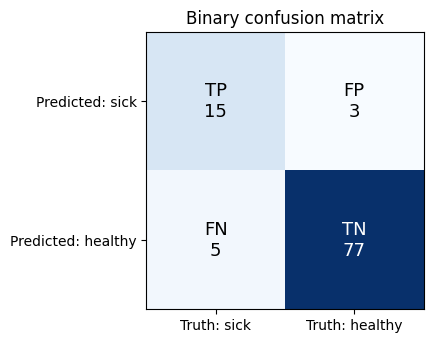

In [2]:
# 1 = sick, 0 = healthy
y_true = np.array([1]*15 + [1]*5 + [0]*3 + [0]*77)
y_pred = np.array([1]*15 + [0]*5 + [1]*3 + [0]*77)

tp, fp, fn, tn = binary_counts(y_true, y_pred)
print(f"TP = {tp}   FP = {fp}   FN = {fn}   TN = {tn}   (total = {tp+fp+fn+tn})")

fig, ax = plt.subplots(figsize=(4.2, 3.6))
cm = np.array([[tp, fp], [fn, tn]])
ax.imshow(cm, cmap="Blues")
names = [["TP", "FP"], ["FN", "TN"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{names[i][j]}\n{cm[i, j]}", ha="center", va="center",
                color="white" if cm[i, j] > 40 else "black", fontsize=13)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Truth: sick", "Truth: healthy"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Predicted: sick", "Predicted: healthy"])
ax.set_title("Binary confusion matrix")
plt.savefig("figures/01_binary_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

### 1.2 The four basic metrics

| Metric | Formula | The question it answers |
|---|---|---|
| **Accuracy** | (TP + TN) / total | How often is the model right overall? |
| **Precision** | TP / (TP + FP) | When it says "positive", can I trust it? |
| **Recall** | TP / (TP + FN) | Of all the real positives, how many did it find? |
| **F1** | 2·TP / (2·TP + FP + FN) | High only if precision **and** recall are both high |

**Precision and recall pull against each other.** Which one matters more depends on the cost of each mistake: a spam filter needs precision (don't lose real emails), medical screening needs recall (don't miss a sick patient).

In [3]:
print(f"Accuracy  = {accuracy(y_true, y_pred):.2f}")
print(f"Precision = {precision(tp, fp):.2f}")
print(f"Recall    = {recall(tp, fn):.2f}")
print(f"F1        = {f1(tp, fp, fn):.2f}")

# Check with scikit-learn
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
print("\nscikit-learn:", round(accuracy_score(y_true, y_pred), 2), round(precision_score(y_true, y_pred), 2),
      round(recall_score(y_true, y_pred), 2), round(f1_score(y_true, y_pred), 2))

Accuracy  = 0.92
Precision = 0.83
Recall    = 0.75
F1        = 0.79

scikit-learn: 0.92 0.83 0.75 0.79


### 1.3 The accuracy trap: class imbalance

A "lazy" model always answers **"healthy"**. It finds no sick patient at all. What is its accuracy?

In [4]:
y_lazy = np.zeros_like(y_true)
tp_l, fp_l, fn_l, tn_l = binary_counts(y_true, y_lazy)
print(f"Lazy model -> accuracy = {accuracy(y_true, y_lazy):.2f}   recall = {recall(tp_l, fn_l):.2f}   F1 = {f1(tp_l, fp_l, fn_l):.2f}")

Lazy model -> accuracy = 0.80   recall = 0.00   F1 = 0.00


**80% accuracy without finding a single sick patient!** Since 80% of the X-rays are healthy, answering "healthy" every time is enough. Recall and F1 (both 0) reveal the truth.

> **Key takeaway:** when one class is much bigger than the other, accuracy is misleading.

### 1.4 The decision threshold

In reality, the model doesn't answer "yes" or "no": it gives a **score** between 0 and 1. We then choose a **threshold**: score ≥ threshold → positive.

- The threshold is **chosen on the validation set**, then **applied once on the test set**.
- Changing the threshold changes TP, FP, FN, and therefore precision and recall.

Example with 6 patients:

In [5]:
scores6 = np.array([0.9, 0.7, 0.4, 0.6, 0.3, 0.2])
truth6  = np.array([1,   1,   1,   0,   0,   0  ])   # 1 = sick

print(f"{'Threshold':<11}{'Flagged':<9}{'TP':>4}{'FP':>4}{'FN':>4}{'Precision':>11}{'Recall':>8}")
for t in [0.8, 0.5, 0.35]:
    pred = apply_threshold(scores6, t)
    tp_, fp_, fn_, _ = binary_counts(truth6, pred)
    print(f"{t:<11}{pred.sum():<9}{tp_:>4}{fp_:>4}{fn_:>4}{precision(tp_, fp_):>11.2f}{recall(tp_, fn_):>8.2f}")

Threshold  Flagged    TP  FP  FN  Precision  Recall
0.8        1           1   0   2       1.00    0.33
0.5        3           2   1   1       0.67    0.67
0.35       4           3   1   0       0.75    1.00


**Same model, same scores, different results depending on the threshold.** Strict threshold → high precision, low recall. Loose threshold → high recall, more false alarms. For screening, a low threshold (0.35) catches every sick patient.

### 1.5 ROC-AUC: judging the model without choosing a threshold

**The idea:** pick one sick patient and one healthy patient at random. **AUC** is the probability that the model gives the **sick one the higher score**.
- AUC = 1: perfect ranking. AUC = 0.5: no better than a coin flip.

The **ROC curve** plots, for every possible threshold, the recall (true positive rate) against the false positive rate = FP / (FP + TN). AUC is **the area under this curve**.

AUC (counting pairs) = 0.889   (8 pairs ranked correctly out of 9)
AUC (scikit-learn)   = 0.889


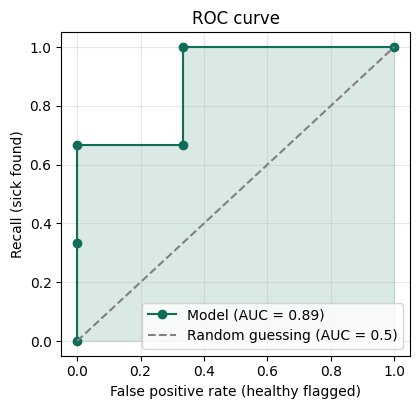

In [6]:
print(f"AUC (counting pairs) = {roc_auc_pairs(truth6, scores6):.3f}   (8 pairs ranked correctly out of 9)")

from sklearn.metrics import roc_auc_score, roc_curve
print(f"AUC (scikit-learn)   = {roc_auc_score(truth6, scores6):.3f}")

fpr, tpr, _ = roc_curve(truth6, scores6)
plt.figure(figsize=(4.5, 4.2))
plt.plot(fpr, tpr, "o-", color="#0F6E56", label=f"Model (AUC = {roc_auc_score(truth6, scores6):.2f})")
plt.fill_between(fpr, tpr, alpha=0.15, color="#0F6E56")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random guessing (AUC = 0.5)")
plt.xlabel("False positive rate (healthy flagged)"); plt.ylabel("Recall (sick found)")
plt.title("ROC curve"); plt.legend(loc="lower right"); plt.grid(alpha=0.3)
plt.savefig("figures/01_roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()

> **Key takeaway (binary):** the confusion matrix gives TP/FP/FN/TN; accuracy, precision, recall and F1 come from it; these values depend on the threshold; AUC judges the model's ranking across all thresholds.

---
## 2. Multiclass classification

Each image gets **exactly one** class among several. The confusion matrix becomes **N × N**: rows = truth, columns = prediction, diagonal = correct answers.

Example: 100 images (50 cats, 40 dogs, 10 birds).

Accuracy = diagonal / total = 85 / 100 = 0.85


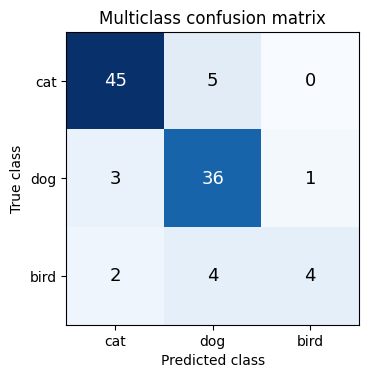

In [7]:
CLASSES = ["cat", "dog", "bird"]
cm_mc = np.array([[45,  5, 0],    # real cats
                  [ 3, 36, 1],    # real dogs
                  [ 2,  4, 4]])   # real birds

# Rebuild the y_true / y_pred lists that produce this matrix
y_true_mc = np.concatenate([[i] * cm_mc[i, j] for i in range(3) for j in range(3)]).astype(int)
y_pred_mc = np.concatenate([[j] * cm_mc[i, j] for i in range(3) for j in range(3)]).astype(int)
assert (confusion_matrix(y_true_mc, y_pred_mc, 3) == cm_mc).all()

fig, ax = plt.subplots(figsize=(4.2, 3.8))
ax.imshow(cm_mc, cmap="Blues")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm_mc[i, j], ha="center", va="center", color="white" if cm_mc[i, j] > 25 else "black", fontsize=13)
ax.set_xticks(range(3)); ax.set_xticklabels(CLASSES); ax.set_yticks(range(3)); ax.set_yticklabels(CLASSES)
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title("Multiclass confusion matrix")
plt.savefig("figures/01_multiclass_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Accuracy = diagonal / total = {np.trace(cm_mc)} / {cm_mc.sum()} = {np.trace(cm_mc) / cm_mc.sum():.2f}")

### 2.1 Per-class metrics

Each class takes its turn being "the positive", and everything else is "the negative":
- **TP** = its diagonal cell
- **FN** = the rest of its **row** (its images the model called something else)
- **FP** = the rest of its **column** (images of other classes wrongly given this class)

In [8]:
p, r, f = per_class_metrics(cm_mc)
print(f"{'Class':<7}{'Precision':>10}{'Recall':>8}{'F1':>7}")
for name, pi, ri, fi in zip(CLASSES, p, r, f):
    print(f"{name:<7}{pi:>10.2f}{ri:>8.2f}{fi:>7.2f}")

Class   Precision  Recall     F1
cat          0.90    0.90   0.90
dog          0.80    0.90   0.85
bird         0.80    0.40   0.53


### 2.2 The three averages: macro, weighted, micro

We have one F1 per class, but we want **one number**. **Analogy:** a school has three classrooms (50, 40 and 10 students). For "the school's average grade", we can:
- **Macro**: average the three classroom averages; every classroom counts the same.
- **Weighted**: bigger classrooms count more.
- **Micro**: forget the classrooms, put all 100 students together and compute one average (add up all TP, FP, FN).

In [9]:
for avg in ["macro", "weighted", "micro"]:
    print(f"F1 {avg:<9} = {averaged_f1(cm_mc, avg):.2f}   (scikit-learn: {f1_score(y_true_mc, y_pred_mc, average=avg):.2f})")

F1 macro     = 0.76   (scikit-learn: 0.76)
F1 weighted  = 0.84   (scikit-learn: 0.84)
F1 micro     = 0.85   (scikit-learn: 0.85)


**What this shows:** accuracy (0.85) and weighted F1 (0.84) look good, but **macro F1 (0.76) reveals that the model is bad at birds** (recall 0.40: it misses 6 out of 10). Macro gives small classes an equal vote.

- **Macro**: when every class matters equally (especially rare ones).
- **Weighted**: to reflect how often each class really appears.
- **Micro**: for an overall view (in multiclass, micro F1 = accuracy).

### 2.3 Top-1 and top-5 accuracy

The model gives a **ranked list of guesses**, from most to least likely.
- **Top-1**: correct if the **first** guess is right (= normal accuracy).
- **Top-5**: correct if the right answer is **among the first 5 guesses**.

Used on **ImageNet** (1,000 classes, including dozens of very similar dog breeds).

In [10]:
truths  = ["cat", "tangerine", "car", "dog"]
guesses = [["cat", "dog", "fox", "rabbit", "lion"],
           ["orange", "tangerine", "lemon", "peach", "apple"],
           ["truck", "bus", "van", "train", "boat"],
           ["dog", "wolf", "cat", "fox", "bear"]]

for t, g in zip(truths, guesses):
    print(f"{t:<10} -> {g}   top-1: {'✓' if g[0] == t else '✗'}   top-5: {'✓' if t in g[:5] else '✗'}")
print(f"\nTop-1 accuracy = {top_k_accuracy(truths, guesses, 1):.2f}")
print(f"Top-5 accuracy = {top_k_accuracy(truths, guesses, 5):.2f}")

cat        -> ['cat', 'dog', 'fox', 'rabbit', 'lion']   top-1: ✓   top-5: ✓
tangerine  -> ['orange', 'tangerine', 'lemon', 'peach', 'apple']   top-1: ✗   top-5: ✓
car        -> ['truck', 'bus', 'van', 'train', 'boat']   top-1: ✗   top-5: ✗
dog        -> ['dog', 'wolf', 'cat', 'fox', 'bear']   top-1: ✓   top-5: ✓

Top-1 accuracy = 0.50
Top-5 accuracy = 0.75


> **Key takeaway (multiclass):** compute precision, recall and F1 **per class**, then average. **How you average decides whether rare classes are visible.**

---
## 3. Multilabel classification

An image can have **several labels at once**. The trick: **each label is a separate yes/no question**, like several binary classifications in parallel.

Example: 3 photos, 3 possible labels (beach, sunset, people).

| Photo | Truth | Prediction |
|---|---|---|
| 1 | beach, sunset | beach |
| 2 | people | people |
| 3 | beach, people | beach, people, sunset |

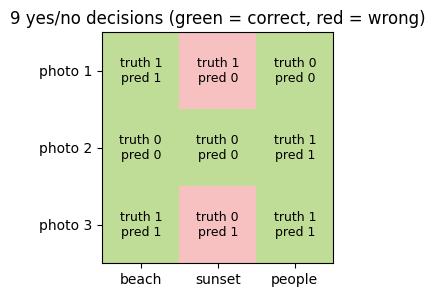

In [11]:
LABELS = ["beach", "sunset", "people"]
Y_true = np.array([[1, 1, 0],
                   [0, 0, 1],
                   [1, 0, 1]])
Y_pred = np.array([[1, 0, 0],
                   [0, 0, 1],
                   [1, 1, 1]])

fig, ax = plt.subplots(figsize=(4.6, 3))
ok = (Y_true == Y_pred).astype(int)
ax.imshow(ok, cmap=ListedColormap(["#F7C1C1", "#C0DD97"]), vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"truth {Y_true[i, j]}\npred {Y_pred[i, j]}", ha="center", va="center", fontsize=9)
ax.set_xticks(range(3)); ax.set_xticklabels(LABELS)
ax.set_yticks(range(3)); ax.set_yticklabels(["photo 1", "photo 2", "photo 3"])
ax.set_title("9 yes/no decisions (green = correct, red = wrong)")
plt.savefig("figures/01_multilabel_decisions.png", dpi=150, bbox_inches="tight")
plt.show()

**9 yes/no decisions, 2 wrong:** "sunset" missed on photo 1 (FN), "sunset" added on photo 3 (FP).

- **Subset accuracy (exact match):** a photo counts only if **all** its labels are exactly right. Very strict.
- **Hamming loss:** fraction of wrong yes/no decisions. More forgiving. **Lower is better.**
- **Per-label F1**, then **macro** or **micro** average (same logic as multiclass).

In [12]:
print(f"Subset accuracy = {subset_accuracy(Y_true, Y_pred):.2f}   (only photo 2 is perfect)")
print(f"Hamming loss    = {hamming_loss(Y_true, Y_pred):.2f}   (2 wrong decisions out of 9)\n")

tp_l, fp_l, fn_l = multilabel_counts(Y_true, Y_pred)
print(f"{'Label':<8}{'TP':>4}{'FP':>4}{'FN':>4}{'F1':>7}")
f1_labels = []
for name, a, b, c in zip(LABELS, tp_l, fp_l, fn_l):
    f1_labels.append(f1(a, b, c))
    print(f"{name:<8}{a:>4}{b:>4}{c:>4}{f1_labels[-1]:>7.2f}")
print(f"\nMacro F1 = {np.mean(f1_labels):.2f}   Micro F1 = {f1(tp_l.sum(), fp_l.sum(), fn_l.sum()):.2f}")

from sklearn.metrics import hamming_loss as sk_hamming
print(f"\nscikit-learn: subset acc = {accuracy_score(Y_true, Y_pred):.2f}, hamming = {sk_hamming(Y_true, Y_pred):.2f}, "
      f"macro F1 = {f1_score(Y_true, Y_pred, average='macro'):.2f}, micro F1 = {f1_score(Y_true, Y_pred, average='micro'):.2f}")

Subset accuracy = 0.33   (only photo 2 is perfect)
Hamming loss    = 0.22   (2 wrong decisions out of 9)

Label     TP  FP  FN     F1
beach      2   0   0   1.00
sunset     0   1   1   0.00
people     2   0   0   1.00

Macro F1 = 0.67   Micro F1 = 0.80

scikit-learn: subset acc = 0.33, hamming = 0.22, macro F1 = 0.67, micro F1 = 0.80


**What this shows:** macro F1 (0.67) reveals that the label "sunset" is completely failed (F1 = 0), while micro F1 (0.80) partly hides it.

---
## 4. Summary

| Type | Key metrics | Main idea |
|---|---|---|
| **Binary** | Accuracy, precision, recall, F1, ROC-AUC | Results depend on the threshold; AUC judges the ranking across all thresholds |
| **Multiclass** | Accuracy, per-class P/R/F1, macro / micro / weighted averages, top-5 | How you average decides whether rare classes are visible |
| **Multilabel** | Subset accuracy, Hamming loss, per-label F1 (macro / micro) | Each label is a yes/no question; strict vs. forgiving scores |

**The common thread:** the confusion matrix is always the base. The metrics only differ in **what counts as one item** (an image, a label) and **how the results are averaged**.